# LeetCode #1143: Longest Common Subsequence

https://leetcode.com/problems/longest-common-subsequence/

## Three ways to solve it

| Approach | Time | Space | What that means in practice |
| :--- | :--- | :--- | :--- |
| **Brute force: try every subsequence** | $O(2^m \times n)$ | $O(m)$ | A 1000-letter string has $2^{1000}$ subsequences. Hopeless. |
| **Recursion that remembers each answer** | $O(m \times n)$ | $O(m \times n)$ | Fast, but the calls can nest 2,000 deep. |
| **A table filled row by row ★** | $O(m \times n)$ | $O(m \times n)$ | About a million small steps for two 1000-letter strings. |

`m` and `n` are the two lengths. $O(m \times n)$ means **the work grows with the number of letter pairs**:
1000 × 1000 is a million boxes, each filled with one comparison. $O(2^m)$ means each extra letter doubles
the work.

A **subsequence** keeps some letters of a string in their original order, possibly with gaps: `"ace"` is a
subsequence of `"abcde"`, but `"aec"` is not. A **common subsequence** is one that both strings contain.

## Understanding the methods

### Brute force

List every subsequence of one string and check whether the other contains it. There are $2^m$ of them, so
this only works for tiny inputs.

### Recursion that remembers each answer

Compare the last letters of the two prefixes; the answer for a pair of prefixes depends only on shorter
pairs. Storing each pair's answer the first time makes it fast, but the recursion can nest `m + n` calls
deep, past Python's default limit of 1,000.

### Optimal: a table filled row by row ★ (the one coded below)

`dp[i][j]` is the length of the longest common subsequence of the first `i` letters of `text1` and the first
`j` letters of `text2`. If those two last letters match, `dp[i][j] = dp[i-1][j-1] + 1`; otherwise it's the
better of dropping one letter, `max(dp[i-1][j], dp[i][j-1])`. Filling answers from smaller stored answers is
**dynamic programming**. Each row only reads the row above, so it can shrink to two rows of memory.

**Why this beats the recursive version:** the same boxes in a fixed order, with no recursion to overflow and
no function-call overhead per box.

**Constraints:**
* `1 <= text1.length, text2.length <= 1000`
* `text1` and `text2` consist of only lowercase English characters


## Explain Like I'm a Newbie

### What the question is actually asking

Cross out letters from each string, without reordering, until both say the same thing. How long can that
shared leftover be?

```
text1 = a b c d e        cross out b and d   ->  a c e
text2 = a c e            nothing to cross    ->  a c e      answer 3
```

### The one idea you need: look at the two last letters

Comparing the whole strings at once is overwhelming. So shrink the question to **prefixes** and fill in a
grid of answers:

> **`dp[i][j]` = the length of the longest common subsequence of the first `i` letters of `text1` and the
> first `j` letters of `text2`.**

Now look only at the last letter of each prefix.

- **They match.** Use that letter in both strings at once. What's left is the two prefixes without it:
  `dp[i][j] = dp[i-1][j-1] + 1`, the box **up and to the left**, plus one.
- **They don't match.** They can't both be the last letter of the shared answer, so at least one of them
  is useless here. Drop one and keep the better result: `max(dp[i-1][j], dp[i][j-1])`, the box **above**
  or the box **to the left**.

Row 0 and column 0 are all 0: an empty prefix shares nothing. The bottom-right box is the answer.

### What that means in code

A `(m+1) × (n+1)` grid of zeros, the extra row and column standing for "no letters yet". Two loops fill
it row by row; each box needs the three boxes above, left and up-left, which are always done by then.
Building answers from smaller ones like this is **dynamic programming**.

### Mistakes people make the first time

1. **Counting shared letters.** It passes all three of LeetCode's samples, then says 2 for `"ab"` and
   `"ba"`. Order matters; the answer is 1.
2. **Greedy matching** (take each letter of `text1` at its next position in `text2`). Also passes all
   three samples; on `"cab"` and `"abc"` it locks onto `c` and returns 1 instead of 2.
3. **Using the box above plus one on a match.** Passes the samples, then answers 2 for `"aa"` and `"a"`,
   because the single `a` gets used twice.

### Things worth knowing

The table for two 1000-letter strings is a million numbers. Since each row only reads the one above, two
rows are enough if you only need the length.


## Talking It Through in an Interview

*Written from the interviewer's chair. This is what I'd want to hear from you, from the moment I show you the problem to the moment the code is on the board.*

---

### The 30-second pitch

> **You:** "Define dp[i][j] as the LCS of the first i letters of one string and the first j of the other. Compare the two last letters. If they match, use it in both: up-left plus one. If not, one of them can't end the answer, so take the better of dropping either: max of above and left. Row and column zero are empty prefixes, all zeros. Fill row by row, answer in the corner. That's m times n boxes, a million at the limit, and a million numbers of memory, which I can cut to two rows if you only want the length."

The meaning of a box, both transitions with their reasons, the base and the cost. I can stop worrying after that.

---

### I slide the problem across the table

I write `text1 = "abcde"`, `text2 = "ace"`.

> **You:** "Subsequence, so gaps are allowed but order isn't changed? 'ace' counts, 'aec' doesn't?"

**"Right. And it's just the length."** That restatement matters: a candidate who mixes up subsequence and substring writes a completely different algorithm.

> **You:** "Lengths up to a thousand each? Lowercase only?"

**"Up to 1000, lowercase."** Good. A thousand by a thousand tells you a quadratic table is fine and an exponential search isn't.

---

### Now tell me what's actually hard about it

> **You:** "The tempting thing is to match letters greedily as I walk. On 'cab' versus 'abc' that grabs the c first and is stuck with 1, but 'ab' gives 2. Any single choice I make early can block better ones later, and trying every choice is exponential."

> **You:** "What I can do is look at the last letters. If they're equal, there's an optimal answer that uses them, so I match them and recurse on what's left. If they're not equal, at least one of them isn't in the answer's last spot, so I try dropping each. Those subproblems are just pairs of prefixes, and there are only m times n of them."

That's the hard part named before any technique, with a counter-example to greedy. The prefix pairs as states fall straight out of it.

I sometimes push: "why is it safe to always match equal last letters?"

> **You:** "If the best answer didn't use them, its last letter comes earlier in at least one string, so I could swap it for this pair without making it shorter."

---

### Before you touch the board, tell me the shape and the cost

> **You:** "A grid of (m + 1) by (n + 1) zeros. For i from 1 to m and j from 1 to n: equal letters take up-left plus one, otherwise max of above and left. Return the corner.
>
> Each box is one comparison and one addition or max, so a million boxes is a million steps. Memory is the grid, a million integers; a rolling pair of rows would bring that down to two thousand."

The extra row and column are the detail I listen for. They're what makes `i - 1` and `j - 1` safe without special cases.

---

### Now whiteboard it

```
m, n = len(text1), len(text2)
dp = [[0] * (n + 1) for _ in range(m + 1)]
```

> **You:** "Row 0 and column 0 mean 'no letters yet', and they stay 0. Each row is its own list; multiplying one list would make every row the same object."

That second sentence saves you from a classic Python bug. If you write `[[0] * (n + 1)] * (m + 1)`, I'll ask why every row changes at once.

```
for i in range(1, m + 1):
    for j in range(1, n + 1):
        if text1[i - 1] == text2[j - 1]:
            dp[i][j] = dp[i - 1][j - 1] + 1
        else:
            dp[i][j] = max(dp[i - 1][j], dp[i][j - 1])
return dp[m][n]
```

> **You:** "Box i, j talks about letter i − 1, because of the extra row. On a match it's up-left, not above: above still contains this letter of text2, so above plus one could count it twice."

That's the line I watch. Above plus one passes all three samples and answers 2 for `"aa"` against `"a"`.

---

### Walk me through it before you say you're done

> **You:** "Row a: a matches a, 1; then 1, 1 carried right. Row b: no matches, it copies 1, 1, 1. Row c: c matches c, up-left 1 plus 1 is 2. Row d copies. Row e: e matches e, up-left 2 plus 1, 3. Answer 3, and walking back through the matches gives 'ace'."

> **You:** "And from your clarifier: if the strings shared no letters, nothing would ever match and the corner would stay 0."

---

### Then tell me where it breaks, before I ask

> **You:** "Time is as good as it gets for this problem in general; a million steps is fine. The cost is memory: a million integers, which is 4 MB in C# and several times that as Python lists. If you only need the length, I keep two rows, previous and current, and swap them, which is O(n) memory. Use the shorter string for the columns and it's at most 1,001 numbers."

> **You:** "The catch is that if you also want the subsequence itself, I need the full table, or at least a way to walk back from the corner: a match means go up-left and record the letter, otherwise go toward the larger neighbour."

Both the shrink and the reason not to shrink. That's the contract cost I'd have asked about.

If there's time, I ask how many single-letter inserts and deletes it takes to turn one string into the other.

> **You:** "Every letter outside the common subsequence has to go: deleted from text1 or inserted from text2. So it's m plus n minus twice the LCS. For 'abcde' and 'ace' that's 5 plus 3 minus 6, two deletions. Allow substitutions too and it's edit distance, the same kind of table with a third option per box."

Seeing the same table answer a different question is the generalisation I'm hoping for.

---

### What would worry me

Greedy matching. Confusing subsequence with substring. Above plus one on a match. A grid built with `[[0] * (n + 1)] * (m + 1)`. And a top-down recursion in Python without a word about the 2,000-deep call stack.


## Solutions

All four fill a `(m+1) × (n+1)` table where `dp[i][j]` is the LCS length of the first `i` letters of `text1` and the first `j` of `text2`.

### C#


In [ ]:
public class Solution {
    public int LongestCommonSubsequence(string text1, string text2) {
        int m = text1.Length, n = text2.Length;
        // dp[i, j] = LCS length of the first i letters of text1 and the first j of text2.
        // Row 0 and column 0 stand for "no letters yet" and stay 0.
        int[,] dp = new int[m + 1, n + 1];
        for (int i = 1; i <= m; i++) {
            for (int j = 1; j <= n; j++) {
                // Box (i, j) talks about letters i-1 and j-1 (the extra row/column shifts by one)
                if (text1[i - 1] == text2[j - 1])
                    // Same last letter: use it in BOTH strings, on top of the answer without
                    // either (up-left). Using "above + 1" could count one letter twice.
                    dp[i, j] = dp[i - 1, j - 1] + 1;
                else
                    // Different: one of the two letters can't end the answer, so drop one
                    // (above = drop text1's letter, left = drop text2's) and keep the better
                    dp[i, j] = Math.Max(dp[i - 1, j], dp[i, j - 1]);
            }
        }
        return dp[m, n];
    }
}

### Python

Each row is built by its own `[0] * (n + 1)` inside the comprehension. Writing `[[0] * (n + 1)] * (m + 1)` would put the same row object in the table `m + 1` times, so filling one row would fill them all.


In [ ]:
class Solution:
    def longestCommonSubsequence(self, text1: str, text2: str) -> int:
        m, n = len(text1), len(text2)
        # dp[i][j] = LCS length of the first i letters of text1 and the first j of text2.
        # Row 0 and column 0 stand for "no letters yet" and stay 0.
        dp = [[0] * (n + 1) for _ in range(m + 1)]
        for i in range(1, m + 1):
            for j in range(1, n + 1):
                # Box (i, j) talks about letters i-1 and j-1 (the extra row/column shifts by one)
                if text1[i - 1] == text2[j - 1]:
                    # Same last letter: use it in BOTH strings, on top of the answer without
                    # either (up-left). Using "above + 1" could count one letter twice.
                    dp[i][j] = dp[i - 1][j - 1] + 1
                else:
                    # Different: one of the two letters can't end the answer, so drop one
                    # (above = drop text1's letter, left = drop text2's) and keep the better
                    dp[i][j] = max(dp[i - 1][j], dp[i][j - 1])
        return dp[m][n]

### Go


In [ ]:
func longestCommonSubsequence(text1 string, text2 string) int {
    m, n := len(text1), len(text2)
    // dp[i][j] = LCS length of the first i letters of text1 and the first j of text2.
    // Row 0 and column 0 stand for "no letters yet" and stay 0.
    dp := make([][]int, m+1)
    for i := range dp { dp[i] = make([]int, n+1) }
    for i := 1; i <= m; i++ {
        for j := 1; j <= n; j++ {
            // Box (i, j) talks about letters i-1 and j-1 (the extra row/column shifts by one)
            if text1[i-1] == text2[j-1] {
                // Same last letter: use it in BOTH strings, on top of the answer without
                // either (up-left). Using "above + 1" could count one letter twice.
                dp[i][j] = dp[i-1][j-1] + 1
            } else {
                // Different: one of the two letters can't end the answer, so drop one
                // (above = drop text1's letter, left = drop text2's) and keep the better
                if dp[i-1][j] > dp[i][j-1] {
                    dp[i][j] = dp[i-1][j]
                } else {
                    dp[i][j] = dp[i][j-1]
                }
            }
        }
    }
    return dp[m][n]
}

### Rust


In [ ]:
impl Solution {
    pub fn longest_common_subsequence(text1: String, text2: String) -> i32 {
        let (t1, t2) = (text1.as_bytes(), text2.as_bytes());
        let (m, n) = (t1.len(), t2.len());
        // dp[i][j] = LCS length of the first i letters of text1 and the first j of text2.
        // Row 0 and column 0 stand for "no letters yet" and stay 0.
        let mut dp = vec![vec![0i32; n + 1]; m + 1];
        for i in 1..=m {
            for j in 1..=n {
                // Box (i, j) talks about letters i-1 and j-1 (the extra row/column shifts by one)
                if t1[i-1] == t2[j-1] {
                    // Same last letter: use it in BOTH strings, on top of the answer without
                    // either (up-left). Using "above + 1" could count one letter twice.
                    dp[i][j] = dp[i-1][j-1] + 1;
                } else {
                    // Different: one of the two letters can't end the answer, so drop one
                    // (above = drop text1's letter, left = drop text2's) and keep the better
                    dp[i][j] = dp[i-1][j].max(dp[i][j-1]);
                }
            }
        }
        dp[m][n]
    }
}

## Example Scenarios

### 1. Common Case — LeetCode's Example
**Input:** `text1 = "abcde"`, `text2 = "ace"`

Three boxes are matches that the answer uses, `a`, `c` and `e`, and each takes the box up-left plus one, so
the corner reaches 3. Crossing out `b` and `d` leaves `"ace"` in both. **Output:** `3`

### 2. Slightly Complex — Shared Letters, Mostly Out of Order
**Input:** `text1 = "ezupkr"`, `text2 = "ubmrapg"`

Three letters appear in both, `u`, `p` and `r`, but `p` and `r` come in opposite orders in the two strings,
so only two can line up: `"up"` or `"ur"`. Most boxes just carry the better neighbour along. **Output:** `2`

### 3. Edge Case: Time Factor — Two 1000-Letter Strings
**Input:** `text1 = "a" * 1000`, `text2 = "a" * 1000`

The largest table allowed: 1,001 × 1,001 boxes, about a million steps, and every one is a match, so
`dp[i][j]` is simply the smaller of `i` and `j`. **Output:** `1000`

### 4. Edge Case: Space Factor — Nothing in Common
**Input:** `text1 = "abc"`, `text2 = "def"`

No box ever matches, so every box copies a 0 from above or the left. The input is small; the table always
has `(m + 1) × (n + 1)` boxes whatever the letters, so the real worst case for memory is two 1000-letter
strings, a million numbers. **Output:** `0`

### 5. Almost-Impossible but Plausible — One Shared Letter
**Input:** `text1 = "bl"`, `text2 = "yby"`

Only `b` appears in both. Once it's matched, the max-of-neighbours rule carries that 1 right and down to the
corner, so the stray `y` after it doesn't matter. **Output:** `1`


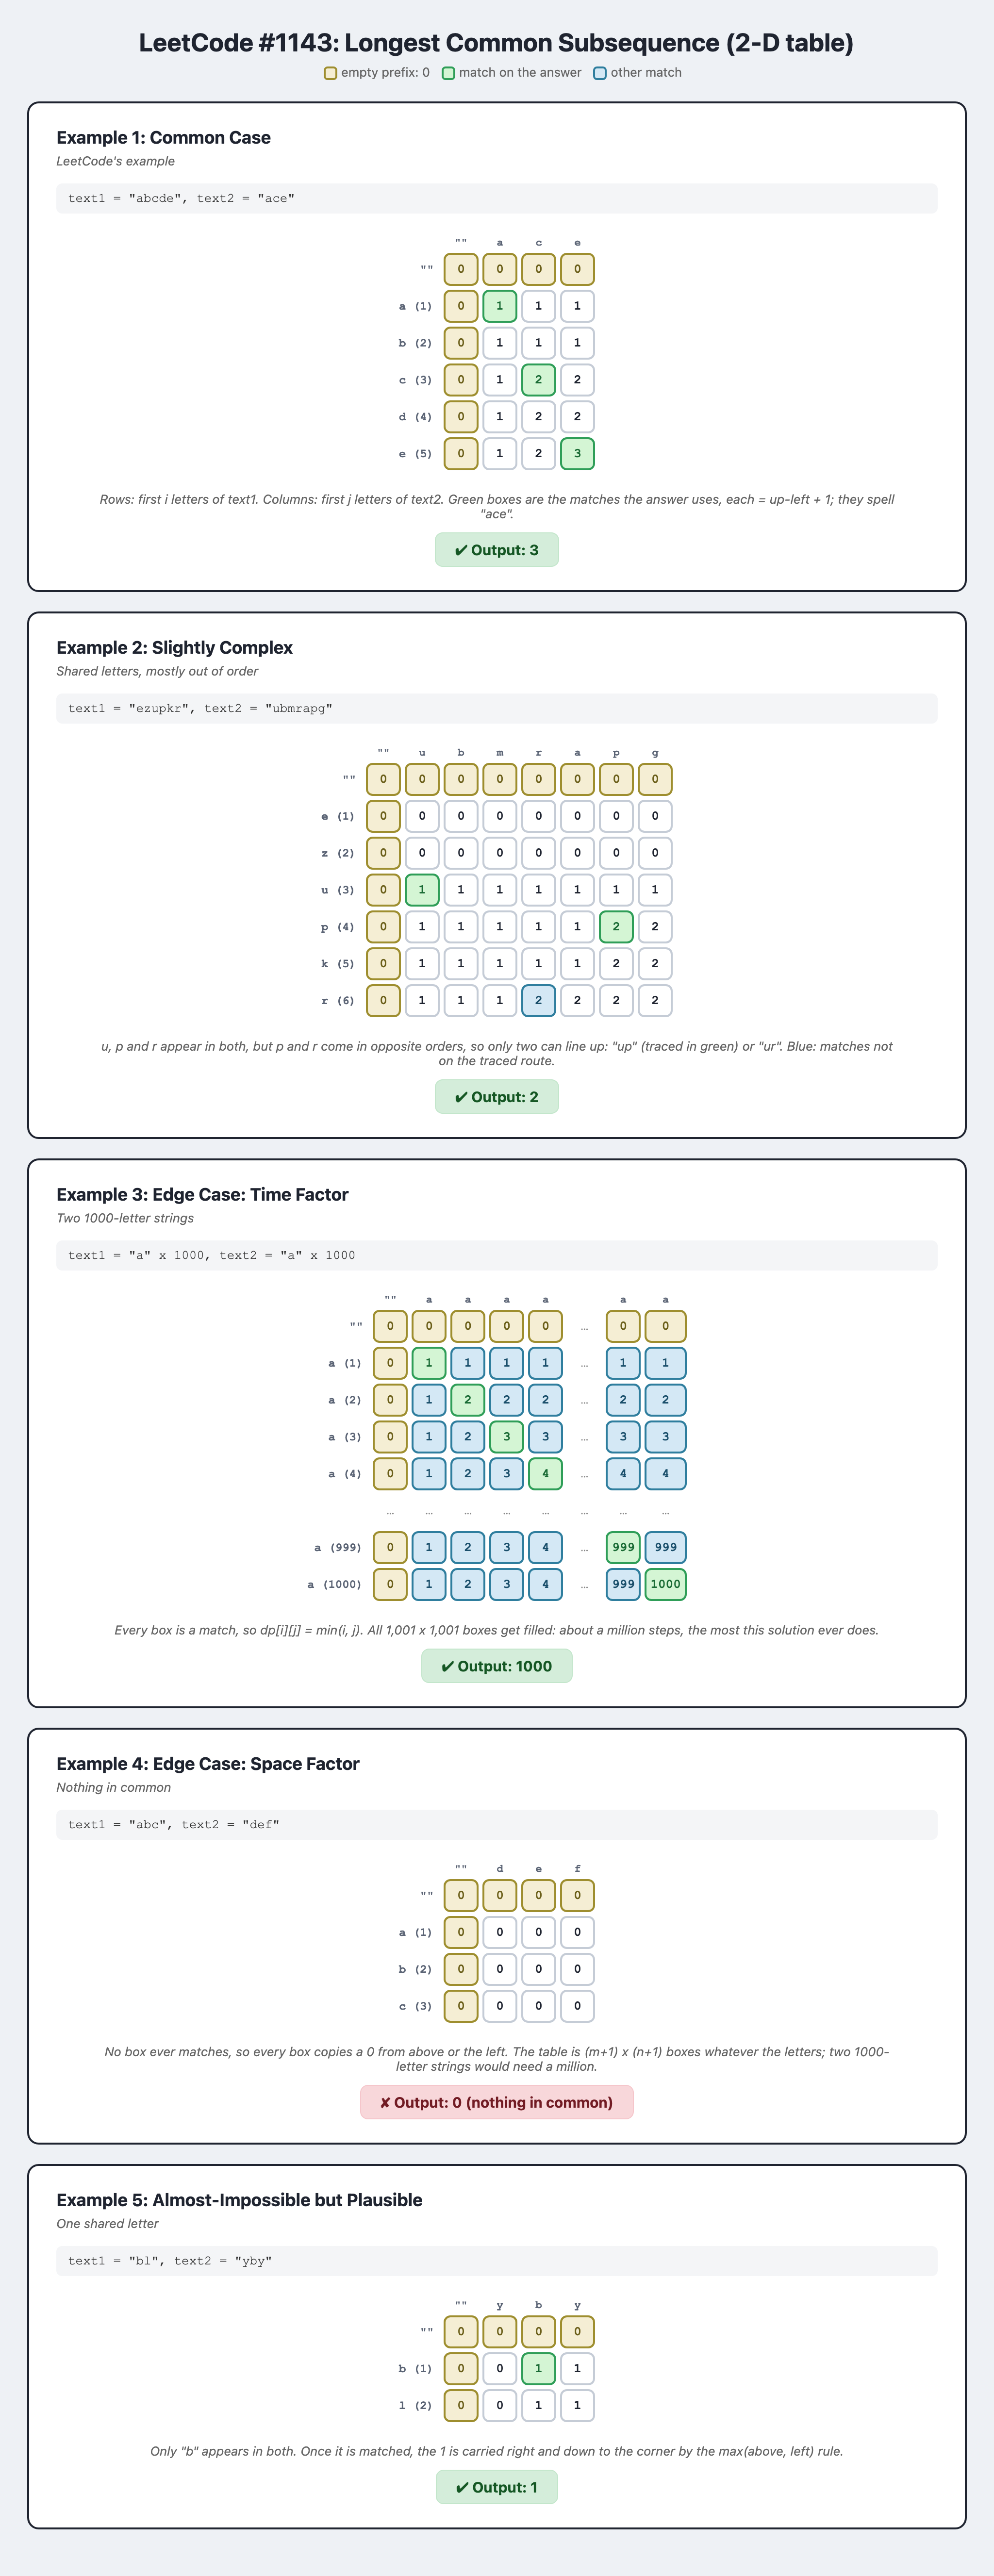

## Watch It Run

*Watch the 'e' box in the corner: the letters match, so it takes the up-left box plus one, never the box above.*

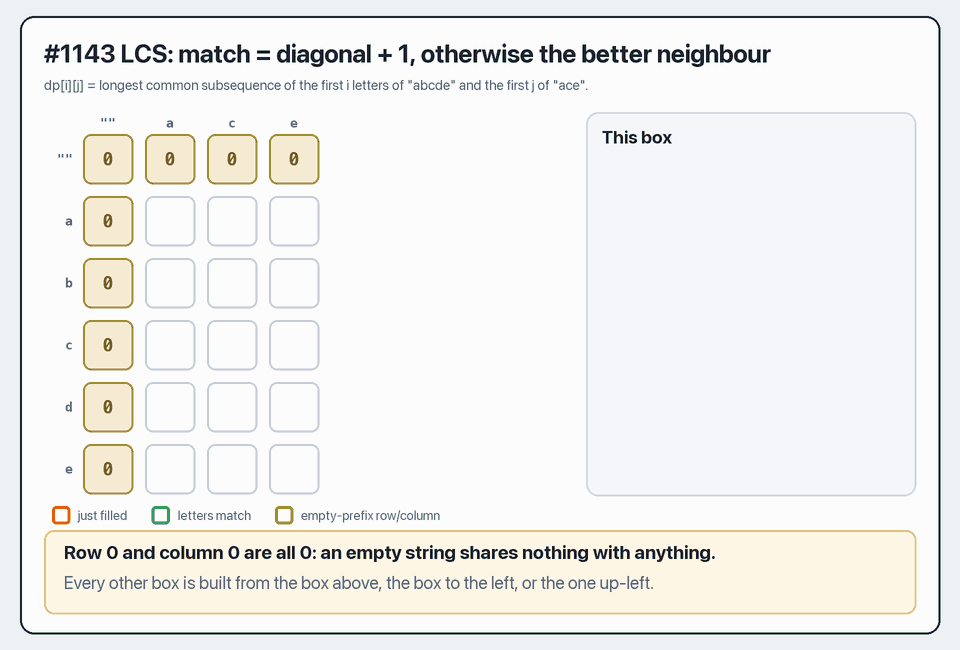